# Vote pondéré de Golub — WDBC
## Classification malin / bénin · Seed : 23


## 1. Configuration


In [25]:
from pathlib import Path
import hashlib
import json
from itertools import combinations
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    balanced_accuracy_score, accuracy_score, roc_curve
)

SEED = 23
DATA = Path("data")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})


## 2. Chargement et intégrité


In [14]:
manifest = json.loads((DATA / "MANIFEST.json").read_text())
sha256 = hashlib.sha256((DATA / "wdbc.csv").read_bytes()).hexdigest()
assert sha256 == manifest["sha256"], "Le CSV ne correspond pas au manifeste."
df = pd.read_csv(DATA / "wdbc.csv")
features = df.columns.drop(["sample_id", "diagnosis"])
X = df[features].to_numpy(dtype=float)
y = df["diagnosis"].map({"benign": 0, "malignant": 1})
assert y.notna().all()
y = y.to_numpy(dtype=int)
assert X.shape == (manifest["rows"], manifest["feature_columns"])
assert df["sample_id"].is_unique
assert np.isfinite(X).all()
assert df["diagnosis"].value_counts().to_dict() == manifest["diagnosis_counts"]
print("SHA256 : conforme")
print("Patients :", len(df), "| Variables :", len(features))
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print(df.head().to_string(index=False))


SHA256 : conforme
Patients : 569 | Variables : 30
Valeurs manquantes : 0
sample_id diagnosis  mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness  mean_compactness  mean_concavity  mean_concave_points  mean_symmetry  mean_fractal_dimension  radius_error  texture_error  perimeter_error  area_error  smoothness_error  compactness_error  concavity_error  concave_points_error  symmetry_error  fractal_dimension_error  worst_radius  worst_texture  worst_perimeter  worst_area  worst_smoothness  worst_compactness  worst_concavity  worst_concave_points  worst_symmetry  worst_fractal_dimension
WDBC-0001 malignant        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33    

## 3. Exploration descriptive
### 3.1. Répartition des diagnostics


           patients  pourcentage
diagnosis                       
benign          357        62.74
malignant       212        37.26


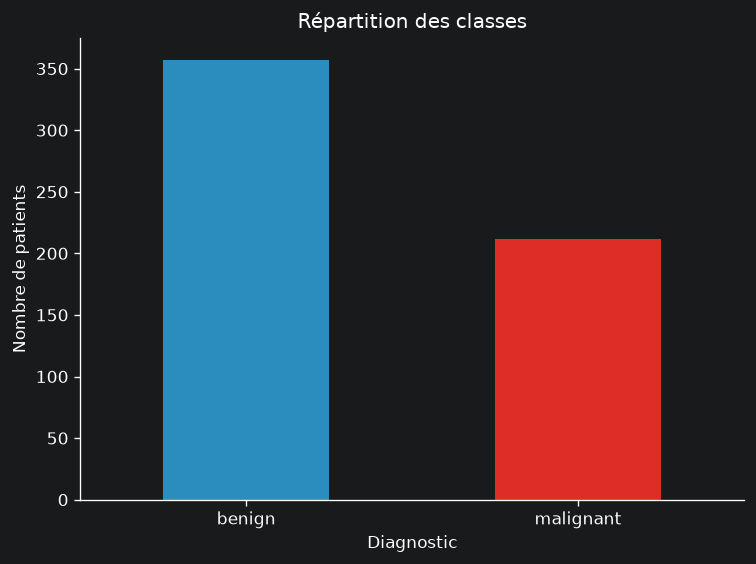

In [15]:
class_counts = df["diagnosis"].value_counts().rename("patients").to_frame()
class_counts["pourcentage"] = 100 * class_counts["patients"] / len(df)
print(class_counts.round(2).to_string())
class_counts.to_csv(OUT / "class_counts.csv")
ax = class_counts["patients"].plot.bar(color=["#2b8cbe", "#de2d26"], rot=0)
ax.set(xlabel="Diagnostic", ylabel="Nombre de patients", title="Répartition des classes")
plt.tight_layout()
plt.savefig(OUT / "class_counts.png")
plt.show()


### 3.2. Variables et origine des mesures

| Résumé | Signification |
|---|---|
| `mean_*` | Moyenne sur les noyaux |
| `*_error` | Erreur standard fournie par la source |
| `worst_*` | Moyenne des trois plus grandes valeurs |

**Propriétés :** radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension.

**Chaîne de mesure :** ponction → lame numérisée → identification des noyaux → extraction des propriétés → 30 valeurs par patient.

### 3.3. Statistiques par diagnostic
Exploration descriptive uniquement : aucune sélection de variables à partir de ces résultats.


diagnosis                       benign  malignant
mean_radius             mean   12.1465    17.4628
                        std     1.7805     3.2040
mean_texture            mean   17.9148    21.6049
                        std     3.9951     3.7795
mean_perimeter          mean   78.0754   115.3654
                        std    11.8074    21.8547
mean_area               mean  462.7902   978.3764
                        std   134.2871   367.9380
mean_smoothness         mean    0.0925     0.1029
                        std     0.0134     0.0126
mean_compactness        mean    0.0801     0.1452
                        std     0.0337     0.0540
mean_concavity          mean    0.0461     0.1608
                        std     0.0434     0.0750
mean_concave_points     mean    0.0257     0.0880
                        std     0.0159     0.0344
mean_symmetry           mean    0.1742     0.1929
                        std     0.0248     0.0276
mean_fractal_dimension  mean    0.0629     0.0627


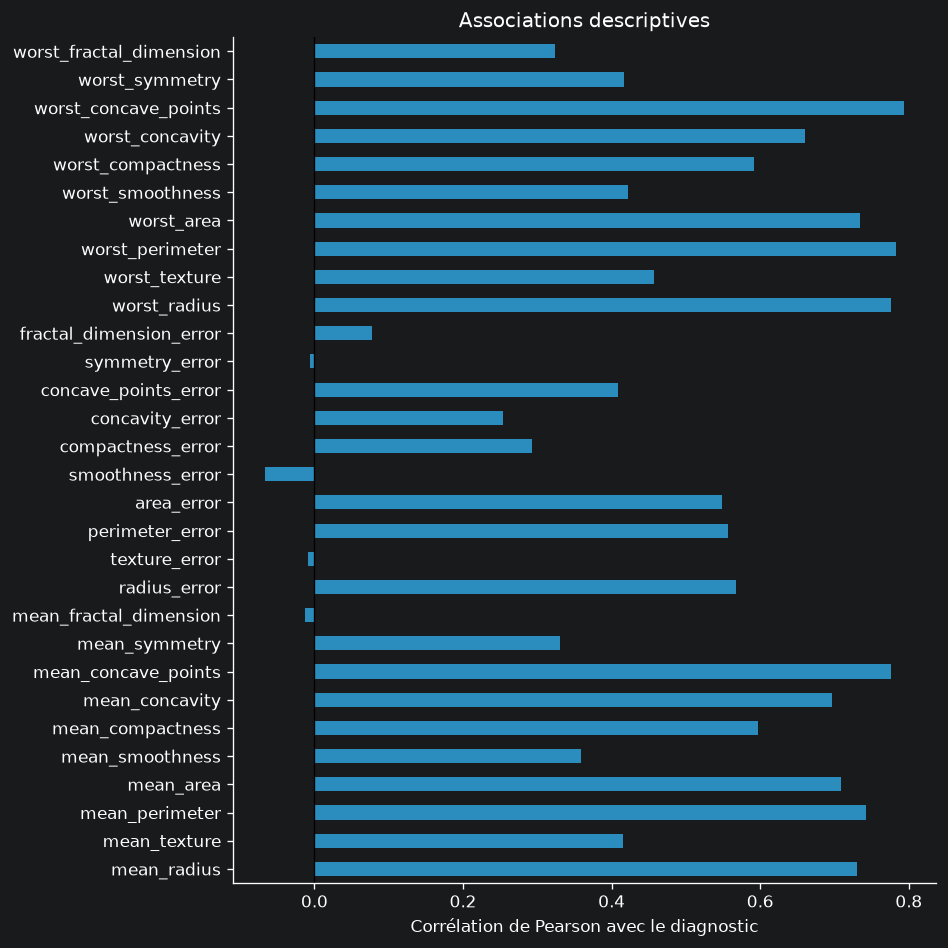

In [16]:
description = df.groupby("diagnosis")[features].agg(["mean", "std"])
print(description.T.round(4).to_string())
description.to_csv(OUT / "descriptive_statistics.csv")

# Corrélation descriptive avec le diagnostic binaire, sans sélection globale.
association = df[features].corrwith(pd.Series(y, index=df.index))
association = association.rename("correlation_diagnostic").to_frame()
print("\nCorrélation avec malin = 1 :")
print(association.round(4).to_string())
association.to_csv(OUT / "feature_label_correlations.csv")

fig, ax = plt.subplots(figsize=(8, 8))
association["correlation_diagnostic"].plot.barh(ax=ax, color="#2b8cbe")
ax.set(xlabel="Corrélation de Pearson avec le diagnostic", title="Associations descriptives")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(OUT / "feature_label_correlations.png")
plt.show()


## 4. Vote pondéré
### 4.1. Implémentation
$$w_j=\frac{\mu_{j,1}-\mu_{j,0}}{\sigma_{j,1}+\sigma_{j,0}},\qquad V(x)=\sum_{j\in S}w_j\left(x_j-\frac{\mu_{j,1}+\mu_{j,0}}{2}\right).$$

**Choix :** 10 variables ; écarts-types avec `ddof=1` ; égalités départagées par l'ordre du CSV ; poids nul si le dénominateur est nul ; malin si $V(x)\geq0$.

**Échelle :** valeurs brutes, conformément à la formule du sujet. Les unités peuvent influencer l'amplitude des votes.


In [17]:
class WeightedVoting:
    def __init__(self, n_features=10):
        self.n_features = n_features

    def fit(self, X_train, y_train):
        # Toutes les estimations utilisent uniquement les patients d'entraînement.
        class0 = X_train[y_train == 0]
        class1 = X_train[y_train == 1]
        mu0, mu1 = class0.mean(axis=0), class1.mean(axis=0)
        denominator = class0.std(axis=0, ddof=1) + class1.std(axis=0, ddof=1)
        self.weights_ = np.divide(mu1 - mu0, denominator,
                                  out=np.zeros_like(mu0), where=denominator > 0)
        self.midpoints_ = (mu0 + mu1) / 2
        self.selected_ = np.argsort(-np.abs(self.weights_), kind="stable")[:self.n_features]
        return self

    def decision_function(self, X_test):
        selected = self.selected_
        return (X_test[:, selected] - self.midpoints_[selected]) @ self.weights_[selected]

    def predict(self, X_test):
        return (self.decision_function(X_test) >= 0).astype(int)


## 5. Validation croisée
### 5.1. 5 plis stratifiés × 3 répétitions
Même liste de 15 partitions pour les deux méthodes ; aucun patient commun entre entraînement et validation dans un pli.

**Régression logistique :** 30 variables ; standardisation sur l'entraînement ; `liblinear`, `C=1.0`, `max_iter=1000`, sans pondération des classes ni optimisation ; seuil 0,5.


In [18]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
splits = list(cv.split(X, y))
records, selections, example, predictions = [], [], {}, []

for fold_index, (train, valid) in enumerate(splits):
    assert not np.intersect1d(train, valid).size
    repeat, fold = fold_index // 5 + 1, fold_index % 5 + 1
    voting = WeightedVoting().fit(X[train], y[train])
    logistic = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=SEED)
    ).fit(X[train], y[train])
    selected_names = set(features[voting.selected_])
    selections.append(selected_names)

    # L'AUC utilise un score continu, jamais les classes prédites.
    evaluations = [
        ("Vote pondéré", voting.predict(X[valid]), voting.decision_function(X[valid])),
        ("Régression logistique", logistic.predict(X[valid]),
         logistic.predict_proba(X[valid])[:, 1])
    ]
    for method, predicted, scores in evaluations:
        tn, fp, fn, tp = confusion_matrix(y[valid], predicted, labels=[0, 1]).ravel()
        records.append({
            "method": method, "repeat": repeat, "fold": fold,
            "n_train": len(train), "n_valid": len(valid),
            "auc": roc_auc_score(y[valid], scores),
            "balanced_accuracy": balanced_accuracy_score(y[valid], predicted),
            "accuracy": accuracy_score(y[valid], predicted),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp
        })
        for i, label, score in zip(valid, predicted, scores):
            predictions.append({"sample_id": df.iloc[i]["sample_id"], "method": method,
                                "repeat": repeat, "fold": fold, "true": int(y[i]),
                                "predicted": int(label), "score": float(score)})
        if fold_index == 0:
            example[method] = (y[valid], predicted, scores)

results = pd.DataFrame(records)
results.to_csv(OUT / "fold_metrics.csv", index=False)
pd.DataFrame(predictions).to_csv(OUT / "validation_predictions.csv", index=False)
# Export explicite des partitions pour la reproductibilité.
partitions = [{"repeat": k // 5 + 1, "fold": k % 5 + 1,
               "train_ids": df.iloc[tr]["sample_id"].tolist(),
               "valid_ids": df.iloc[va]["sample_id"].tolist()}
              for k, (tr, va) in enumerate(splits)]
(OUT / "splits.json").write_text(json.dumps(partitions, indent=2))
print("Partitions :", len(splits))
print(results.round(4).to_string(index=False))


Partitions : 15
               method  repeat  fold  n_train  n_valid    auc  balanced_accuracy  accuracy  sensitivity  specificity  tn  fp  fn  tp
         Vote pondéré       1     1      455      114 0.9712             0.8837    0.9123       0.7674       1.0000  71   0  10  33
Régression logistique       1     1      455      114 1.0000             0.9859    0.9825       1.0000       0.9718  69   2   0  43
         Vote pondéré       1     2      455      114 0.9613             0.8767    0.9035       0.7674       0.9859  70   1  10  33
Régression logistique       1     2      455      114 0.9974             0.9767    0.9825       0.9535       1.0000  71   0   2  41
         Vote pondéré       1     3      455      114 0.9603             0.8026    0.8509       0.6190       0.9861  71   1  16  26
Régression logistique       1     3      455      114 0.9940             0.9762    0.9825       0.9524       1.0000  72   0   2  40
         Vote pondéré       1     4      455      114 0.9521

### 5.2. Exemple fixé à l’avance : répétition 1, pli 1


               method    auc  balanced_accuracy  sensitivity  specificity  tn  fp  fn  tp
         Vote pondéré 0.9712             0.8837       0.7674       1.0000  71   0  10  33
Régression logistique 1.0000             0.9859       1.0000       0.9718  69   2   0  43


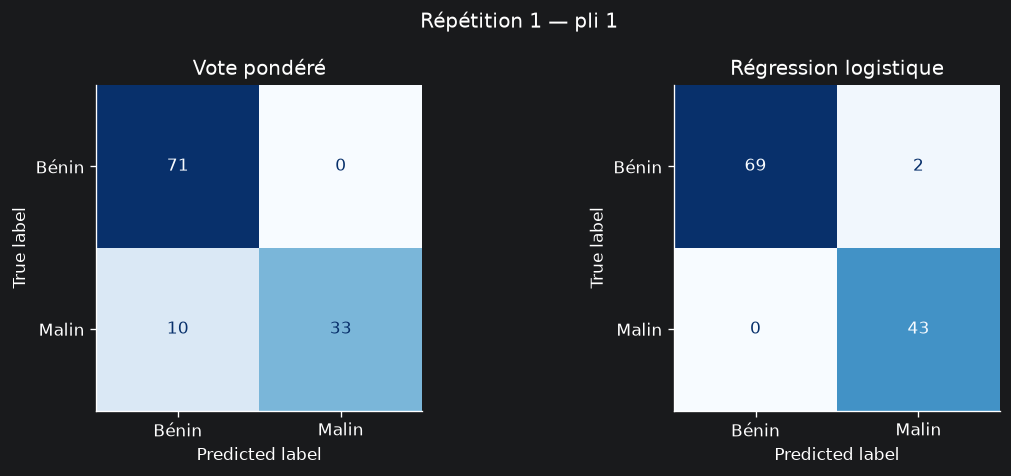

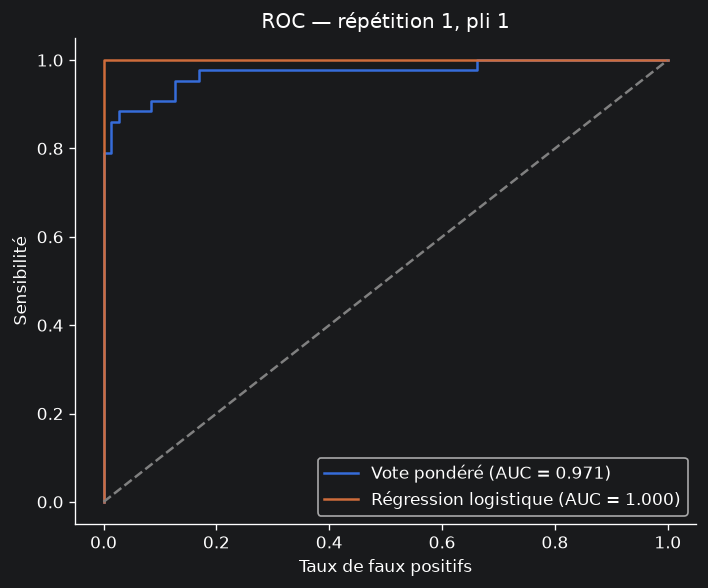

In [19]:
first_fold = results.query("repeat == 1 and fold == 1")
print(first_fold[["method", "auc", "balanced_accuracy", "sensitivity", "specificity",
                  "tn", "fp", "fn", "tp"]].round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (method, (truth, predicted, scores)) in zip(axes, example.items()):
    ConfusionMatrixDisplay.from_predictions(
        truth, predicted, labels=[0, 1], display_labels=["Bénin", "Malin"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(method)
fig.suptitle("Répétition 1 — pli 1")
plt.tight_layout()
plt.savefig(OUT / "example_confusion_matrices.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for method, (truth, predicted, scores) in example.items():
    fpr, tpr, _ = roc_curve(truth, scores)
    ax.plot(fpr, tpr, label=f"{method} (AUC = {roc_auc_score(truth, scores):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="Taux de faux positifs", ylabel="Sensibilité", title="ROC — répétition 1, pli 1")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "example_roc.png")
plt.show()


### 5.3. Performances moyennes sur les 15 modèles
Moyenne et écart-type entre plis ; les plis répétés ne sont pas indépendants. L'écart-type ne constitue pas un intervalle de confiance.


                          auc         balanced_accuracy         accuracy         sensitivity         specificity        
                         mean     std              mean     std     mean     std        mean     std        mean     std
method                                                                                                                  
Régression logistique  0.9947  0.0059            0.9739  0.0085   0.9777  0.0080      0.9590  0.0209      0.9888  0.0152
Vote pondéré           0.9622  0.0125            0.8561  0.0370   0.8893  0.0262      0.7263  0.0792      0.9860  0.0130


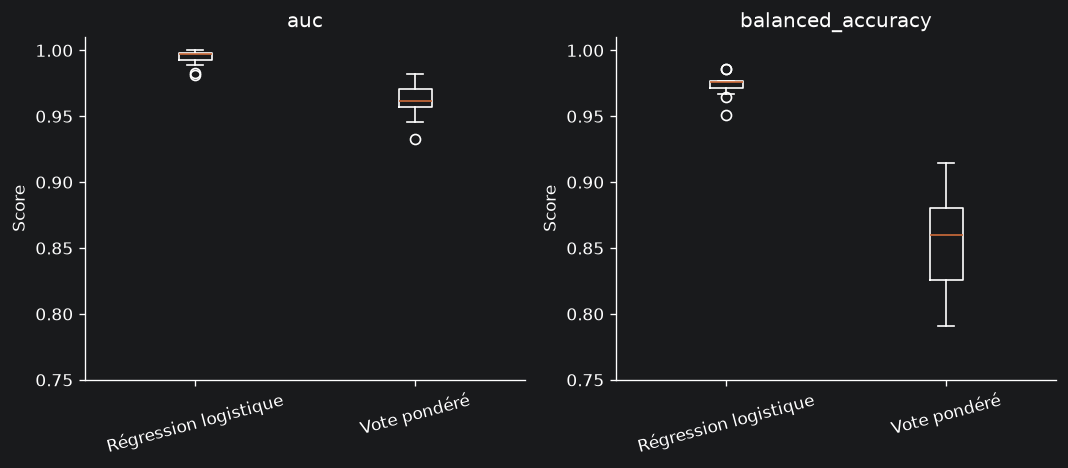

In [20]:
metrics = ["auc", "balanced_accuracy", "accuracy", "sensitivity", "specificity"]
summary = results.groupby("method")[metrics].agg(["mean", "std"])
print(summary.round(4).to_string())
summary.to_csv(OUT / "performance_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, metric in zip(axes, ["auc", "balanced_accuracy"]):
    groups = [group[metric].to_numpy() for _, group in results.groupby("method")]
    names = list(results.groupby("method").groups)
    ax.boxplot(groups, tick_labels=names)
    ax.set(title=metric, ylabel="Score", ylim=(0.75, 1.01))
    ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.savefig(OUT / "performance_distributions.png")
plt.show()


## 6. Stabilité des variables
### 6.1. Sélections et fréquences
$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}.$$


 repeat  fold                                                                                                                                                      features
      1     1 mean_area, mean_concave_points, mean_concavity, mean_perimeter, mean_radius, worst_area, worst_concave_points, worst_concavity, worst_perimeter, worst_radius
      1     2      area_error, mean_area, mean_concave_points, mean_concavity, mean_perimeter, mean_radius, worst_area, worst_concave_points, worst_perimeter, worst_radius
      1     3 mean_area, mean_concave_points, mean_concavity, mean_perimeter, mean_radius, worst_area, worst_concave_points, worst_concavity, worst_perimeter, worst_radius
      1     4 mean_area, mean_concave_points, mean_concavity, mean_perimeter, mean_radius, worst_area, worst_concave_points, worst_concavity, worst_perimeter, worst_radius
      1     5 mean_area, mean_concave_points, mean_concavity, mean_perimeter, mean_radius, worst_area, worst_concave_points, worst_concavity

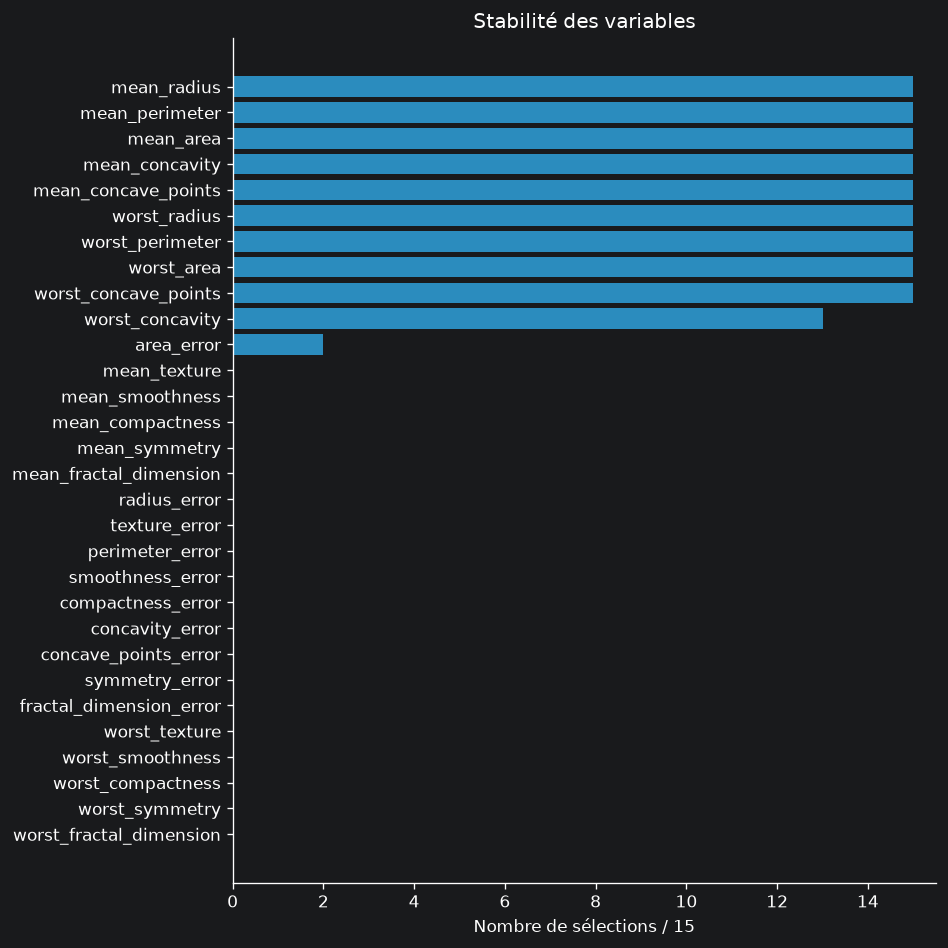

In [21]:
selection_table = pd.DataFrame([
    {"repeat": k // 5 + 1, "fold": k % 5 + 1, "features": ", ".join(sorted(selected))}
    for k, selected in enumerate(selections)
])
selection_table.to_csv(OUT / "selected_features_by_fold.csv", index=False)
print(selection_table.to_string(index=False))

frequency = pd.DataFrame({"feature": features,
                         "count": [sum(f in selected for selected in selections) for f in features]})
frequency["frequency"] = frequency["count"] / len(selections)
frequency = frequency.sort_values("count", ascending=False, kind="stable")
frequency.to_csv(OUT / "selection_frequency.csv", index=False)
print("\n", frequency.to_string(index=False))

jaccards = [len(a & b) / len(a | b) for a, b in combinations(selections, 2)]
mean_jaccard = float(np.mean(jaccards))
print(f"\nJaccard moyen : {mean_jaccard:.4f} ({len(jaccards)} paires)")
(OUT / "stability.json").write_text(json.dumps({"mean_jaccard": mean_jaccard,
                                               "pairs": len(jaccards)}, indent=2))

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(frequency["feature"][::-1], frequency["count"][::-1], color="#2b8cbe")
ax.set(xlabel="Nombre de sélections / 15", title="Stabilité des variables", xlim=(0, 15.5))
plt.tight_layout()
plt.savefig(OUT / "selection_frequency.png")
plt.show()


### 6.2. Stabilité prédictive et identité des variables

**Résultat :** 9 variables sur 10 sont communes aux 15 modèles ; Jaccard moyen 0,955. Pour le vote pondéré, les 569 patients reçoivent chacun la même classe lors des trois validations. Cette stabilité ne garantit pas la justesse : sensibilité moyenne 72,6 %.


In [22]:
wv = results[results["method"] == "Vote pondéré"]
print(f"AUC : {wv.auc.mean():.4f} ± {wv.auc.std():.4f}")
print(f"Balanced accuracy : {wv.balanced_accuracy.mean():.4f} ± {wv.balanced_accuracy.std():.4f}")
print(f"Jaccard moyen : {mean_jaccard:.4f}")
print("Variables sélectionnées dans tous les plis :", int((frequency["count"] == 15).sum()))
# Les mêmes patients sont validés une fois par répétition, donc trois fois au total.
pred_df = pd.DataFrame(predictions)
assert pred_df.groupby(["method", "sample_id"]).size().eq(3).all()
consistency = pred_df.groupby(["method", "sample_id"])["predicted"].nunique().eq(1)
print("Proportion de patients avec une prédiction identique sur les 3 répétitions :")
print(consistency.groupby("method").mean().round(4).to_string())


AUC : 0.9622 ± 0.0125
Balanced accuracy : 0.8561 ± 0.0370
Jaccard moyen : 0.9550
Variables sélectionnées dans tous les plis : 9
Proportion de patients avec une prédiction identique sur les 3 répétitions :
method
Régression logistique    0.9859
Vote pondéré             1.0000


## 7. Comparaison des méthodes
### 7.1. Différences sur les mêmes partitions


In [23]:
paired = results.pivot(index=["repeat", "fold"], columns="method", values=metrics)
differences = pd.DataFrame({
    metric: paired[metric]["Régression logistique"] - paired[metric]["Vote pondéré"]
    for metric in metrics
})
print("Différence : régression logistique − vote pondéré")
print(differences.agg(["mean", "std"]).round(4).to_string())
differences.to_csv(OUT / "paired_differences.csv")


Différence : régression logistique − vote pondéré
         auc  balanced_accuracy  accuracy  sensitivity  specificity
mean  0.0325             0.1178    0.0885       0.2327       0.0028
std   0.0139             0.0364    0.0286       0.0694       0.0193


## 8. Conclusion clinique
### 8.1. Résultats


In [24]:
for method, group in results.groupby("method"):
    print(f"{method} : AUC {group.auc.mean():.3f} ; balanced accuracy "
          f"{group.balanced_accuracy.mean():.3f} ; sensibilité {group.sensitivity.mean():.3f} ; "
          f"spécificité {group.specificity.mean():.3f}.")
print(f"Stabilité de sélection : Jaccard moyen = {mean_jaccard:.3f}.")


Régression logistique : AUC 0.995 ; balanced accuracy 0.974 ; sensibilité 0.959 ; spécificité 0.989.
Vote pondéré : AUC 0.962 ; balanced accuracy 0.856 ; sensibilité 0.726 ; spécificité 0.986.
Stabilité de sélection : Jaccard moyen = 0.955.
